# Passo 5 – Regra de operação: quando entrar (o custo entra aqui)

O modelo (treinado sem custo) entrega, para cada candle, **quanto** prevê que o preço vai andar. A regra decide se essa previsão vale uma operação.

Cenário do Passo 4: **60 min × janela 36 meses × re-treino trimestral** (alternativa: 30 min × 36 m).

| Regra | Opera quando | Ideia |
|---|---|---|
| sempre | todo candle | referência |
| prev > k × custo | \|movimento previsto em pts\| > k × 5 pts (k = 1, 2, 3) | usa diretamente o **tamanho** previsto |
| top X% | \|previsão\| acima do quantil (1−X) das previsões do **trimestre anterior** | limiar relativo, sem espiar o futuro |
| aleatório | mesmos candles da regra, direção sorteada (1.000 vezes) | controle: a direção do modelo ganha da sorte? |

Custo: **5 pts por operação**. Valor em R$: 1 contrato de WIN (R$ 0,20 por ponto).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rf_zero as rz
win_1m = rz.carregar("../../dados/WINN_M1/WIN$N_M1.csv")
CENARIOS = {"60 min × 36 m": 60, "30 min × 36 m": 30}
# walk-forward a partir de 10/2023: o 4º trimestre de 2023 só serve para calibrar o limiar "top X%" de jan/2024
prevs = {}
for nome, m in CENARIOS.items():
    base, cols = rz.montar_base(win_1m, m)
    prevs[nome] = rz.walk_forward(base, cols, ("2023-10-01", rz.VALIDACAO[1]), 36, "QS")
    prevs[nome]["prev_pts"] = rz.prev_pontos(prevs[nome])
{k: len(v) for k, v in prevs.items()}

{'60 min × 36 m': 2397, '30 min × 36 m': 5094}

In [2]:
def direcoes(d, regra, valor=None):
    # devolve direção (+1/−1/0) para os candles de 2024
    v = d[d.index >= rz.VALIDACAO[0]]
    s = np.sign(v["prev_pts"])
    if regra == "sempre":
        return s
    if regra == "custo":
        return s.where(v["prev_pts"].abs() > valor * rz.CUSTO_PTS, 0)
    if regra == "top":
        trimestre = d.index.to_period("Q")
        q = d["prev_pts"].abs().groupby(trimestre).quantile(1 - valor)   # limiar de cada trimestre...
        lim = trimestre[d.index >= rz.VALIDACAO[0]].map(lambda t: q[t - 1])  # ...usado no trimestre SEGUINTE
        return s.where(v["prev_pts"].abs().values > lim.values, 0)

REGRAS = [("sempre", None, "sempre")] + [("custo", k, f"prev > {k}×custo") for k in [1, 2, 3]] + \
         [("top", x, f"top {int(x*100)}%") for x in [0.5, 0.3, 0.2, 0.1]]

rng = np.random.default_rng(42)
def p_aleatorio(mov, res_modelo, n_sim=1000):
    # fração das simulações aleatórias (mesmos candles, direção sorteada) com esperança >= a do modelo
    sims = (rng.choice([-1, 1], size=(n_sim, len(mov))) * mov).mean(axis=1) - rz.CUSTO_PTS
    return (sims >= res_modelo).mean()

linhas, resultados = {}, {}
for nome, d in prevs.items():
    v = d[d.index >= rz.VALIDACAO[0]]
    for regra, valor, rotulo in REGRAS:
        dirc = direcoes(d, regra, valor)
        op = dirc != 0
        res = rz.resultado_operacoes(dirc.values, v["mov_prox"].values)
        r = rz.resumo_ops(res, v.index[op.values])
        r["p vs aleatório"] = p_aleatorio(v["mov_prox"].values[op.values], res.mean())
        linhas[(nome, rotulo)] = r
        resultados[(nome, rotulo)] = pd.Series(res, index=v.index[op.values])
tab = pd.DataFrame(linhas).T
tab.to_csv("saidas/passo05_regras.csv")
tab.round(2)

n_ops  esperança pts/op     t  acerto %  \
60 min × 36 m sempre          2004.0              7.04  1.03     50.70   
              prev > 1×custo  1595.0             12.61  1.63     51.41   
              prev > 2×custo  1205.0             11.47  1.25     51.54   
              prev > 3×custo   845.0             11.99  1.09     52.54   
              top 50%         1037.0             13.39  1.38     52.17   
              top 30%          581.0             16.95  1.16     52.84   
              top 20%          409.0             26.99  1.45     54.52   
              top 10%          226.0             36.44  1.45     53.54   
30 min × 36 m sempre          4259.0              1.28  0.37     49.33   
              prev > 1×custo  2982.0              3.65  0.89     49.93   
              prev > 2×custo  1256.0             -4.63 -0.65     48.81   
              prev > 3×custo   591.0             -0.47 -0.04     49.24   
              top 50%         2028.0             -0.83 -0.16     49.16   
              top 30%         1197.0              0.85  0.12     49.04   
              top 20%          810.0             -2.38 -0.24     49.26   
              top 10%          419.0             -2.53 -0.16     48.45   

                              trimestres +  total pts  total R$ (1 contrato)  \
60 min × 36 m sempre                   3.0    14105.0                 2821.0   
              prev > 1×custo           4.0    20105.0                 4021.0   
              prev > 2×custo           3.0    13825.0                 2765.0   
              prev > 3×custo           3.0    10130.0                 2026.0   
              top 50%                  3.0    13885.0                 2777.0   
              top 30%                  3.0     9850.0                 1970.0   
              top 20%                  3.0    11040.0                 2208.0   
              top 10%                  3.0     8235.0                 1647.0   
30 min × 36 m sempre                   3.0     5435.0                 1087.0   
              prev > 1×custo           4.0    10885.0                 2177.0   
              prev > 2×custo           1.0    -5810.0                -1162.0   
              prev > 3×custo           3.0     -275.0                  -55.0   
              top 50%                  1.0    -1680.0                 -336.0   
              top 30%                  2.0     1020.0                  204.0   
              top 20%                  1.0    -1930.0                 -386.0   
              top 10%                  2.0    -1060.0                 -212.0   

                              drawdown máx pts  p vs aleatório  
60 min × 36 m sempre                    7860.0            0.04  
              prev > 1×custo            4610.0            0.01  
              prev > 2×custo            5710.0            0.04  
              prev > 3×custo            5530.0            0.04  
              top 50%                   4020.0            0.04  
              top 30%                   5180.0            0.05  
              top 20%                   4560.0            0.04  
              top 10%                   3805.0            0.05  
30 min × 36 m sempre                   16075.0            0.03  
              prev > 1×custo            9870.0            0.02  
              prev > 2×custo           11155.0            0.49  
              prev > 3×custo            7850.0            0.37  
              top 50%                  14760.0            0.22  
              top 30%                   9855.0            0.23  
              top 20%                   8195.0            0.38  
              top 10%                   9075.0            0.44

**Como ler:** *esperança* e *total* já descontam 5 pts por operação. *p vs aleatório* = em quantas das 1.000 simulações com direção sorteada (nos mesmos candles) o resultado foi igual ou melhor que o do modelo – quanto menor, menos provável que seja sorte (p < 0,05 ≈ t > 2).

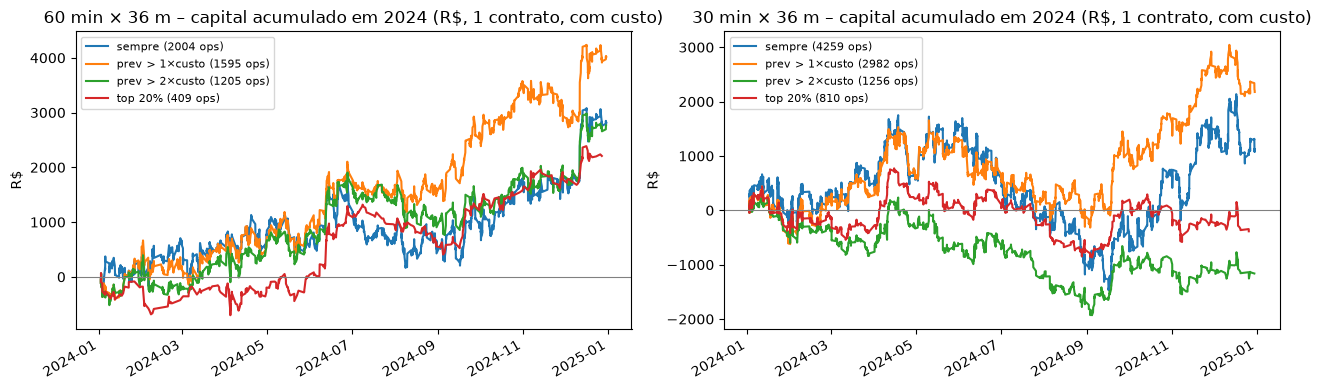

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for a, nome in zip(axs, CENARIOS):
    for regra, valor, rotulo in REGRAS:
        if rotulo in ["sempre", "prev > 1×custo", "prev > 2×custo", "top 20%"]:
            r = resultados[(nome, rotulo)]
            (r.cumsum() * rz.REAIS_POR_PONTO["WIN"]).plot(ax=a, label=f"{rotulo} ({len(r)} ops)")
    a.axhline(0, color="gray", lw=.8); a.set_title(f"{nome} – capital acumulado em 2024 (R$, 1 contrato, com custo)")
    a.set_ylabel("R$"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("passo05_curvas_capital.png", dpi=120); plt.show()

In [4]:
# esperança líquida por trimestre de cada regra (consistência)
pd.DataFrame({k: v.groupby(v.index.quarter).mean() for k, v in resultados.items()}).T.round(1).rename(columns=lambda q: f"T{q}")

T1    T2    T3    T4
60 min × 36 m sempre           6.5   6.9  -3.5  19.1
              prev > 1×custo   8.0  16.3   7.8  18.0
              prev > 2×custo   5.8  23.1  -7.4  24.1
              prev > 3×custo -16.7  30.1   5.5  22.9
              top 50%         -2.7  25.9   0.8  26.2
              top 30%        -32.8  34.1   9.8  36.1
              top 20%        -21.4  42.9  11.0  49.8
              top 10%         -6.0  57.3  24.1  42.0
30 min × 36 m sempre           2.3   1.1  -4.7   6.9
              prev > 1×custo   1.6   3.0   2.4   9.7
              prev > 2×custo -11.1   3.1  -5.9  -7.3
              prev > 3×custo -18.6   7.7   1.6   9.9
              top 50%         -1.0  -5.1  -0.4   7.4
              top 30%         -3.1  10.0 -10.0   5.0
              top 20%         -7.2  13.0  -1.2 -18.6
              top 10%        -17.8   0.1  -3.5  20.4

## 5.1 Sensibilidade ao custo

E se o custo real for diferente de 5 pts? Esperança por operação da regra com custo de 0 a 15 pts (cenário 60 min).

In [5]:
sens = {}
for rotulo in ["sempre", "prev > 1×custo", "prev > 2×custo", "top 20%"]:
    bruto = resultados[("60 min × 36 m", rotulo)] + rz.CUSTO_PTS
    sens[rotulo] = {c: bruto.mean() - c for c in [0, 2, 5, 10, 15]}
pd.DataFrame(sens).T.round(2).rename(columns=lambda c: f"custo {c} pts")

,custo 0 pts,custo 2 pts,custo 5 pts,custo 10 pts,custo 15 pts
sempre,12.04,10.04,7.04,2.04,-2.96
prev > 1×custo,17.61,15.61,12.61,7.61,2.61
prev > 2×custo,16.47,14.47,11.47,6.47,1.47
top 20%,31.99,29.99,26.99,21.99,16.99


## Conclusões do Passo 5

1. **Regra escolhida: "só opera se o movimento previsto > custo" (k = 1), no candle de 60 min.** Esperança líquida de **+12,6 pts/op**, positiva nos **4 trimestres** de 2024, 1.595 operações, **+R$ 4.021** com 1 contrato e o menor drawdown entre as regras de maior lucro. É também a regra menos arbitrária: usa diretamente o **tamanho** previsto (o "quanto sobe ou desce") e compara com o que a operação custa.
2. **Filtrar mais nem sempre ajuda.** As regras "top X%" têm esperança por operação maior (até +36 pts), mas operam pouco, perdem no 1º trimestre e somam menos no total – a esperança alta vem de poucas operações e é instável.
3. **30 min descartado.** Fora a regra k = 1, todas as regras no 30 min ficam perto de zero ou negativas, e o resultado não se distingue do aleatório (p de 0,2 a 0,5).
4. **Dois testes, duas perguntas:**
   * *p vs aleatório* = 0,01 → a **direção** escolhida pelo modelo é melhor que sorte nos mesmos candles;
   * *t* = 1,6 → o **lucro líquido** ainda não é estatisticamente diferente de zero com um só ano de dados. Ainda abaixo do t ≥ 2 que exigimos.
5. **Folga para o custo.** A regra empata só com custo de ~17,6 pts por operação; com 10 pts ainda dá +7,6 pts/op.

➡️ **Cenário até aqui:** WIN, candle 60 min, janela 36 meses, re-treino trimestral, 17 variáveis, regra "|previsto| > 5 pts". Falta o ajuste fino da árvore (Passo 6).
